# Part 3: Data quality in weather and reservoir filling

This notebook prepares 1,000 reproducible weather locations in each of eight areas
and demonstrates DCT/SPC, Local Outlier Factor (LOF), STL and a spectrogram.
The notebook and Streamlit import the same download and analysis functions.
The example uses **sampled-area NO3 weather in 2024** and **all available NO3
weekly filling history**.


In [1]:
# Allow imports whether Jupyter starts in the repository root or notebooks/.
import sys
from pathlib import Path
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "ind320").is_dir())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))


In [2]:
from pathlib import Path
import logging
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from ind320.config import ROOT
from ind320.data.areas import load_weather_areas, sample_weather_points
from ind320.data.weather import fetch_weather, daily_weather, load_weather_coordinates
from ind320.data.reservoirs import fetch_reservoir_history
from ind320.analysis.weather import precipitation_analysis, temperature_analysis
from ind320.analysis.reservoirs import weekly_filling, stl_analysis, filling_spectrogram

2026-11-16 12:19:24.269 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-11-16 12:19:24.270 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


## Area definitions and reproducible sampling

`Budomraader/` supplies NO1–NO5 electricity-area polygons. `NVE_Region/` supplies
five administrative regions. East combines **RS + RØ**, West uses **RV**, and
North combines **RM + RN**. These groups approximate precipitation areas; they
are not exact catchment or VASS boundaries. The app maps them to VASS 1, 2 and 3
for its shared area selector, while retaining this geographic limitation.

Each area has 1,000 locations sampled uniformly in the supplied projected
coordinate system (EPSG:25833), with seed 320. **All sampled locations contribute
to its weather average**; no single representative point is substituted.


In [3]:
# Save all 8,000 sampled locations as JSON for the notebook and deployed app.
import json
areas = load_weather_areas()
candidates, _ = sample_weather_points(areas, count=1000, seed=320)
coordinates = candidates.assign(
    latitude=candidates.geometry.y, longitude=candidates.geometry.x
)[["area", "latitude", "longitude"]]
coordinate_path = ROOT / "data" / "weather_coordinates.json"
coordinate_path.parent.mkdir(exist_ok=True)
coordinate_path.write_text(json.dumps({
    "seed": 320, "points_per_area": 1000, "sampling_crs": "EPSG:25833",
    "coordinate_crs": "EPSG:4326", "points": coordinates.to_dict("records"),
}, indent=2) + "\n")
display(coordinates.groupby("area", sort=False).agg(
    points=("latitude", "size"), mean_latitude=("latitude", "mean"),
    mean_longitude=("longitude", "mean"),
).round(5))


,points,mean_latitude,mean_longitude
area,,,
NO1,1000,60.92447,10.81389
NO2,1000,59.09058,7.38351
NO3,1000,63.02367,8.70687
NO4,1000,68.63818,19.44383
NO5,1000,60.74667,7.01323
East,1000,60.14323,9.11636
West,1000,61.48182,6.37894
North,1000,67.71105,17.84311


In [4]:
# Check every sampled location, deterministic reruns, and the committed JSON.
assert len(areas) == 8 and areas.geometry.is_valid.all()
assert candidates.groupby("area").size().eq(1000).all()
projected_candidates = candidates.to_crs(areas.crs)
for area, polygon in areas.geometry.items():
    assert projected_candidates.loc[candidates["area"] == area].within(polygon).all()
repeated, _ = sample_weather_points(areas, count=1000, seed=320)
assert candidates.equals(repeated)
saved = load_weather_coordinates()
assert len(saved) == 8000 and saved.groupby(level=0).size().eq(1000).all()
assert set(saved.index) == set(areas.index)
assert np.allclose(saved[["latitude", "longitude"]], coordinates[["latitude", "longitude"]])
print("PASS: all 8,000 reproducible interior locations saved and used for weather averaging.")


PASS: all 8,000 reproducible interior locations saved and used for weather averaging.


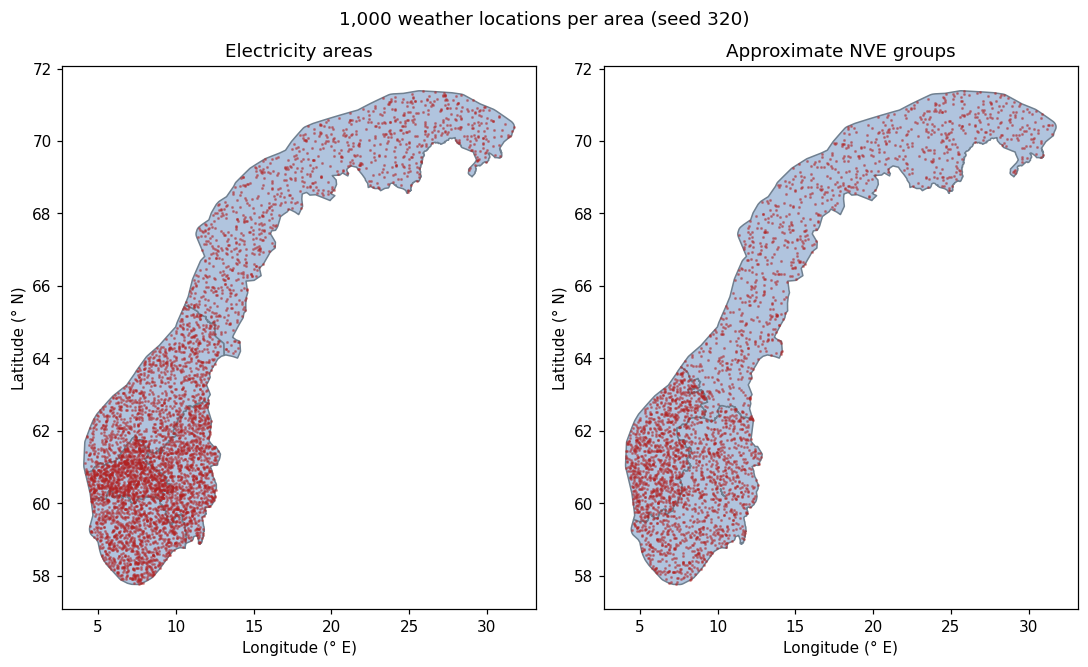

In [5]:
# Show all sampled points, keeping the two overlapping area systems separate.
fig, axes = plt.subplots(1, 2, figsize=(10, 6))
for ax, names, title in zip(
    axes, [list(areas.index[:5]), list(areas.index[5:])],
    ["Electricity areas", "Approximate NVE groups"],
):
    areas.loc[names].to_crs(4326).plot(ax=ax, color="lightsteelblue", edgecolor="slategray")
    candidates.loc[candidates["area"].isin(names)].plot(ax=ax, color="firebrick", markersize=1, alpha=0.4)
    ax.set(title=title, xlabel="Longitude (° E)", ylabel="Latitude (° N)")
fig.suptitle("1,000 weather locations per area (seed 320)")
fig.tight_layout()
plt.show()


## Hourly ERA5 weather for NO3, 2024

The [Open-Meteo Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api)
provides Copernicus ERA5 reanalysis on a 0.25° grid. The downloader maps all
1,000 sampled locations to their nearest grid cells, requests each distinct
cell once, and weights it by the number of sampled locations in that cell.
This estimates the area mean from the sampled locations. Equal weighting of
distinct cells would change that estimate and is not used.

Requests explicitly use ERA5, nearest-cell selection, disabled elevation
downscaling (`elevation=nan`), precipitation, temperature and UTC. The coarse
grid limits spatial detail and can extend across polygon boundaries.
The downloader checks complete hourly coverage for **every** cell before
including it. Batches and local JSON caches avoid repeated downloads; API
rate limits can still interrupt a first full-year download. Rerun to resume
cached cells rather than accepting a partial spatial mean.

January 1–December 31, 2024 has **8,784 hours and 366 days**. UTC avoids
daylight-saving gaps and duplicated hours. Daily precipitation is the mean
hourly amount, not the total daily rainfall.


In [ ]:
# Every sampled point contributes through its nearest ERA5 cell and sample weight.
hourly = fetch_weather("NO3", "2024-01-01", "2024-12-31")
daily = daily_weather(hourly)
print("Sampled points:", hourly.attrs["sampled_points"])
print("Distinct ERA5 cells:", hourly.attrs["grid_cells"])
print("Spatial method:", hourly.attrs["spatial_method"])
assert hourly.attrs["sampled_points"] == 1000
assert hourly.attrs["grid_cells"] > 1
display(daily.head())


In [ ]:
# Check leap-year coverage, UTC, source units, and correct daily averaging.
expected_hours = pd.date_range("2024-01-01", "2024-12-31 23:00", freq="h", tz="UTC")
assert hourly.index.equals(expected_hours) and len(hourly) == 8784
assert str(hourly.index.tz) == "UTC" and len(daily) == 366
assert hourly.notna().all().all() and np.isfinite(hourly.to_numpy()).all()
assert (hourly.precipitation >= 0).all()
assert np.allclose(daily.iloc[0], hourly.iloc[:24].mean())
assert np.allclose(daily.precipitation * 24, hourly.precipitation.resample("D").sum())
print("PASS: 8,784 complete UTC hours and 366 daily averages, including February 29.")

In [ ]:
# Daily plots retain distinct units; averaging rainfall amounts is not summing them.
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].plot(daily.index, daily.precipitation)
axes[0].set(title="NO3 sampled-area average, 2024", ylabel="Average hourly amount (mm)")
axes[1].plot(daily.index, daily.temperature_2m, color="darkorange")
axes[1].set(xlabel="UTC date", ylabel="Temperature (°C)")
fig.tight_layout()
plt.show()

## Precipitation: DCT high-pass filter and robust SPC

The Discrete Cosine Transform (DCT) expresses the daily series as cosine
coefficients from slow to fast variation. We set the first **eight** coefficients
(including the mean) to zero and invert the transform. The remaining signal
emphasizes faster changes. Setting the cutoff to zero returns the original
series. Raising the cutoff removes more slow variation; it is not an exact
calendar-season adjustment. Eight coefficients over 366 days correspond roughly
to removing variations slower than a few months. Boundary effects and the
chosen interval can affect the result.

For robust statistical process control (SPC), calculate the median of the
filtered values and estimate sigma as **1.4826 × MAD**, where MAD is the median
absolute deviation from that median. Flag residuals outside median ± **3 sigma**
over the full selected year. If MAD is zero, the function explicitly falls back
to sample standard deviation. Limits are translated back onto the original
precipitation series so the flagged dates remain interpretable. Only the original precipitation, translated limits and flagged dates are plotted;
filtered values remain internal to the calculation. Lower limits can be negative
even though rainfall itself is nonnegative.

**Assignment wording conflict:** the task applies DCT to precipitation but calls
its output “seasonally adjusted temperature variations” in one sentence. This
implementation follows the precipitation instruction and labels the filtered
result as precipitation. No temperature interpretation is assigned to it.

Rainfall is skewed and autocorrelated, so these are exploratory SPC flags, not
calibrated normal-tail probabilities or proof of data errors. The cutoff and
multiplier are adjustable in the app.

In [ ]:
# Shared analysis returns plot data, a concise summary, and the same figure used in the app.
precipitation, precipitation_summary, fig = precipitation_analysis(daily.precipitation)
print(precipitation_summary)
plt.show()
display(precipitation.loc[precipitation.outlier, ["precipitation", "filtered"]].head())

In [ ]:
# Temperature: the same DCT high-pass filter and robust SPC used above.
# This approximates seasonal adjustment; it is separate from temperature LOF below.
from scipy.fft import dct, idct
from scipy.stats import median_abs_deviation

# Remove the mean and seven other slow cosine components from daily temperature.
temperature_values = daily.temperature_2m.to_numpy(dtype=float)
temperature_coefficients = dct(temperature_values, norm="ortho")
temperature_coefficients[:8] = 0
temperature_filtered = idct(temperature_coefficients, norm="ortho")
temperature_baseline = temperature_values - temperature_filtered

# Estimate robust limits on the fluctuations, with the same zero-MAD fallback.
temperature_center = float(np.median(temperature_filtered))
temperature_sigma = float(median_abs_deviation(temperature_filtered, scale="normal"))
if temperature_sigma == 0:
    temperature_sigma = float(np.std(temperature_filtered, ddof=1))
temperature_lower = temperature_center - 3 * temperature_sigma
temperature_upper = temperature_center + 3 * temperature_sigma
temperature_flags = (
    (temperature_filtered < temperature_lower)
    | (temperature_filtered > temperature_upper)
)
temperature_dct = pd.DataFrame(
    {"temperature_2m": temperature_values, "baseline": temperature_baseline,
     "filtered": temperature_filtered, "outlier": temperature_flags},
    index=daily.index,
)

# Plot original temperature and translated limits, keeping filtered values internal.
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(daily.index, temperature_values, label="Daily average temperature")
ax.fill_between(
    daily.index, temperature_baseline + temperature_lower,
    temperature_baseline + temperature_upper, alpha=0.15, label="SPC limits",
)
ax.scatter(daily.index[temperature_flags], temperature_values[temperature_flags],
           color="firebrick", marker="x", label="Flagged day")
ax.set(title="Temperature: DCT and robust SPC", xlabel="UTC date", ylabel="Temperature (°C)")
ax.legend(fontsize="small")
fig.tight_layout()
plt.show()

# Original-scale and filtered-scale flags must agree; components reconstruct the input.
assert np.allclose(temperature_baseline + temperature_filtered, temperature_values)
assert np.array_equal(
    temperature_flags,
    (temperature_values < temperature_baseline + temperature_lower)
    | (temperature_values > temperature_baseline + temperature_upper),
)
print(f"DCT/SPC: {temperature_flags.sum()} of {len(daily)} days flagged (exploratory flags).")
display(temperature_dct.loc[temperature_dct.outlier])


In [ ]:
# Inspect sensitivity instead of treating defaults as universal weather thresholds.
rows = []
for cutoff in [4, 8, 16]:
    for multiplier in [2.0, 3.0, 4.0]:
        _, summary, check_fig = precipitation_analysis(daily.precipitation, cutoff, multiplier)
        rows.append({"cutoff": cutoff, "multiplier": multiplier, "flagged_days": summary["outliers"]})
        plt.close(check_fig)
display(pd.DataFrame(rows).pivot(index="cutoff", columns="multiplier", values="flagged_days"))
print("Default flags (% of days):", round(100 * precipitation.outlier.mean(), 1))

In [ ]:
# Highlight the detected dates on the original temperature timeline.
temperature, temperature_summary, fig = temperature_analysis(daily.temperature_2m)
print(temperature_summary)
plt.show()
display(temperature.loc[temperature.outlier])

In [ ]:
# Check LOF output and the effect of moving the score threshold.
assert temperature.index.equals(daily.index)
assert np.allclose(temperature.temperature_2m, daily.temperature_2m)
assert np.isfinite(temperature.lof_score).all()
assert temperature_summary["outliers"] == int(temperature.outlier.sum())
more_flags, _, check_fig = temperature_analysis(daily.temperature_2m, contamination=0.05)
assert more_flags.outlier.sum() >= temperature.outlier.sum()
assert (more_flags.outlier | ~temperature.outlier).all()
plt.close(check_fig)
print("PASS: original temperatures retained; higher contamination includes the default flags.")

## Full weekly reservoir history

The [NVE Magasinstatistikk API](https://biapi.nve.no/magasinstatistikk/swagger/index.html)
returns all available filling observations. We select **EL 3 (NO3)**, independently
of the weather year. Fractions are converted to percentages once. Each row in the
series represents one week, not one month or one year.

STL and the spectrogram need equally spaced samples. The shared preparation
function creates a seven-day grid between the first and last available dates.
It interpolates only internal missing weeks in time and reports their count.
It rejects duplicate or off-grid dates rather than silently averaging them.
Interpolation can smooth local variation and must be considered when interpreting
the plots. At least 104 weeks are required for the two annual cycles.

In [ ]:
# Use the existing cached public NVE downloader, without any month/year filter.
reservoir_source = fetch_reservoir_history()
weekly = weekly_filling(reservoir_source, "EL", 3)
print(f"NO3 full history: {weekly.index.min():%Y-%m-%d} to {weekly.index.max():%Y-%m-%d}")
print(f"{len(weekly)} weeks; {weekly.attrs['interpolated_weeks']} interpolated weeks.")
assert len(weekly) >= 104 and np.isfinite(weekly).all()
assert (weekly.index.to_series().diff().dropna() == pd.Timedelta(weeks=1)).all()
original = reservoir_source.loc[
    (reservoir_source["Area Type"] == "EL") & (reservoir_source["Area Code"] == 3)
].set_index("Observation Date")["Fill Level"]
assert np.allclose(weekly.loc[original.dropna().index], original.dropna() * 100)
# A deliberately removed internal week must be reported and interpolated.
gap_source = reservoir_source.copy()
gap_source = gap_source.loc[~(
    (gap_source["Area Type"] == "EL") & (gap_source["Area Code"] == 3)
    & (gap_source["Observation Date"] == weekly.index[10])
)]
gap_weekly = weekly_filling(gap_source, "EL", 3)
assert len(gap_weekly) == len(weekly)
assert gap_weekly.attrs["interpolated_weeks"] == weekly.attrs["interpolated_weeks"] + 1
print("PASS: weekly spacing, percentage conversion, full coverage, and gap reporting.")

## STL: trend, seasonality, and residuals

[STL](https://www.statsmodels.org/stable/generated/statsmodels.tsa.seasonal.STL.html)
uses local smoothing to decompose observed filling into additive trend, seasonal,
and residual components. The seasonal **period is fixed at 52 weeks**, an
approximation to a calendar year that also contains occasional ISO week 53.

The seasonal smoother defaults to **13** and governs how much the seasonal pattern
can change across years. The trend smoother defaults to **105 weeks**; increasing
it produces a slower trend. Both lengths must be odd, and the trend must exceed
52. Robust fitting defaults to true and reduces the effect of large residuals.
The app exposes all three settings. Component sizes use percentage points (pp),
while the original filling level is shown as a percentage.

In [ ]:
# Decompose all available weeks; this is not restricted to the weather year 2024.
components, stl_summary, fig = stl_analysis(weekly)
print(stl_summary)
plt.show()

In [ ]:
# Reconstruction is an essential check for an additive decomposition.
assert components.index.equals(weekly.index)
assert np.allclose(components.trend + components.seasonal + components.residual, weekly)
changed_components, _, check_fig = stl_analysis(weekly, seasonal=21, trend=157, robust=False)
assert not np.allclose(changed_components.trend, components.trend)
assert not np.allclose(changed_components.seasonal, components.seasonal)
plt.close(check_fig)
print("PASS: additive reconstruction and response to STL smoothing/robust controls.")

## Spectrogram: changing cycles over time

The spectrogram divides the same weekly history into overlapping Hann windows
and estimates the power spectral density (PSD) in each window. The default window
is **104 weeks**, with **52 weeks of overlap**. Each window is detrended by
subtracting its mean. Longer windows improve frequency resolution but blur when
changes happen. More overlap gives closer window centers; it does not increase
the underlying frequency resolution.

Sampling frequency is **one observation per week**. Frequencies are in
**cycles/week**, so an annual cycle is approximately **1/52 cycles/week** and the
Nyquist frequency is **0.5 cycles/week**. Time is plotted at the window-center
date. Density is in **pp²/(cycles/week)** and displayed in decibels relative to
one unit of that density. A stronger color indicates stronger variation at that
frequency, not a higher filling level. The 104-week default resolves frequencies
in steps of 1/104 cycles/week, placing an annual cycle at the second nonzero bin.

In [ ]:
# Shared spectrum data has frequency rows and dated window-center columns.
spectrum, spectrum_summary, fig = filling_spectrogram(weekly)
print(spectrum_summary)
plt.show()

In [ ]:
# Validate dimensions/units and recover a known annual signal in a controlled example.
assert np.isfinite(spectrum.to_numpy()).all() and (spectrum.to_numpy() >= 0).all()
assert spectrum.shape[0] == 104 // 2 + 1
assert np.isclose(spectrum.index.max(), 0.5)
assert np.isclose(np.diff(spectrum.index).mean(), 1 / 104)
assert (spectrum.columns.to_series().diff().dropna() == pd.Timedelta(weeks=52)).all()
changed_spectrum, _, check_fig = filling_spectrogram(weekly, window=156, overlap=104)
assert changed_spectrum.shape[0] != spectrum.shape[0]
plt.close(check_fig)
annual = pd.Series(
    50 + 10 * np.sin(2 * np.pi * np.arange(520) / 52),
    index=pd.date_range("2000-01-02", periods=520, freq="7D"), name="Known annual signal"
)
_, known_summary, check_fig = filling_spectrogram(annual)
assert np.isclose(known_summary["peak_period_weeks"], 52)
plt.close(check_fig)
print("PASS: nonnegative spectrum, time/frequency units, window controls, and known annual cycle.")

## AI-tool use

I used AI to help develop and revise the API code, shared analysis functions,
Streamlit controls, documentation and regression checks. After peer feedback,
AI also helped replace single-point weather with sample-weighted area averages,
synchronize area selection, remove filtered SPC curves and reorganize notebooks.
I remain responsible for understanding the methods, checking results and
verifying the final submission. Automated checks with simulated API responses
verify behavior; they do not replace rerunning the notebook with live data.

## Compulsory-work log

Part 3 adds weather and data-quality analysis to the Norwegian reservoir dashboard. The Jupyter Notebook documents preparation, calculations and checks, while Streamlit makes the analyses interactive. Both import the same weather downloader and analysis functions, keeping their calculations consistent.

The supplied shapefiles define five electricity areas, NO1 to NO5, and three grouped NVE regions: East, West and North. The grouped regions approximate precipitation areas rather than exact catchments. With seed 320, the notebook samples 1,000 locations inside each area. Following feedback, all 8,000 locations are saved as JSON, replacing the coordinate CSV. Every sampled location contributes to its area's weather average instead of selecting only one point.

Weather comes from hourly ERA5 precipitation and temperature. Sampled locations are mapped to the nearest 0.25-degree cells. Each distinct cell is downloaded once and weighted by its sampled-point count. Requests use nearest-cell selection with elevation downscaling disabled. Complete hourly coverage is checked for each cell before averaging; incomplete responses cannot silently change the spatial weights. Completed cells are cached locally so interrupted downloads can resume. The NO3 example covers 2024, including February 29. Daily precipitation is the mean hourly amount, not the daily rainfall total.

A DCT filter separates precipitation into slower variation and faster fluctuations. Robust SPC limits flag unusual deviations. The figure now displays only original precipitation, translated limits and flagged dates. A supplementary temperature example uses the same approach, and LOF separately highlights rare temperatures. Flags suggest observations to inspect; they do not prove measurement errors.

STL separates the full weekly reservoir history into trend, seasonal variation and residuals. A spectrogram shows how cycle strength changes over time. Reconstruction checks and a known annual signal help verify the calculations. Window length and overlap remain adjustable in the app.

The weather, reservoir analysis, table and plot pages now share an area selection. The Home page describes Part 3, and the README explains setup and the project structure. Notebooks are collected in a dedicated folder. The existing video was reviewed alongside the notebook and app; a follow-up demonstration checklist includes the spectrogram controls. The [public repository](https://github.com/dared22/ind320) and [Streamlit app](https://cklqlkatpe9mqyrnuch2ma.streamlit.app/) provide the project links. The revisions address the peer-review feedback before Part 4.
